In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv("amazon.csv", sep=",", encoding="utf-8")  # sem on_bad_lines="skip", veja a nota abaixo

# Preços: remove ₹ e vírgulas -> número (continua em rupias)
for col in ["discounted_price", "actual_price"]:
    df[col + "_inr"] = pd.to_numeric(
        df[col].str.replace("₹", "", regex=False).str.replace(",", "", regex=False),
        errors="coerce",
    )

# Desconto: "64%" -> 0.64
df["discount_pct"] = pd.to_numeric(
    df["discount_percentage"].str.replace("%", "", regex=False), errors="coerce"
) / 100

# Rating: o "|" vira NaN
df["rating"] = pd.to_numeric(df["rating"], errors="coerce")

# Quantidade de avaliações: remove vírgula; vazios viram NaN
df["rating_count"] = pd.to_numeric(
    df["rating_count"].str.replace(",", "", regex=False), errors="coerce"
)

# Valor do desconto em rupias
df["discount_value_inr"] = df["actual_price_inr"] - df["discounted_price_inr"]

# Conferência
print(df.shape)
print(df[["discounted_price_inr", "actual_price_inr", "discount_pct", "rating", "rating_count"]].dtypes)
print(df[["discounted_price_inr", "actual_price_inr", "discount_pct", "rating", "rating_count"]].isnull().sum())

(1465, 20)
discounted_price_inr    float64
actual_price_inr        float64
discount_pct            float64
rating                  float64
rating_count            float64
dtype: object
discounted_price_inr    0
actual_price_inr        0
discount_pct            0
rating                  1
rating_count            2
dtype: int64


In [3]:
df["discounted_price_inr"].map("₹{:,.0f}".format).head()

,discounted_price_inr
0,₹399
1,₹199
2,₹199
3,₹329
4,₹154


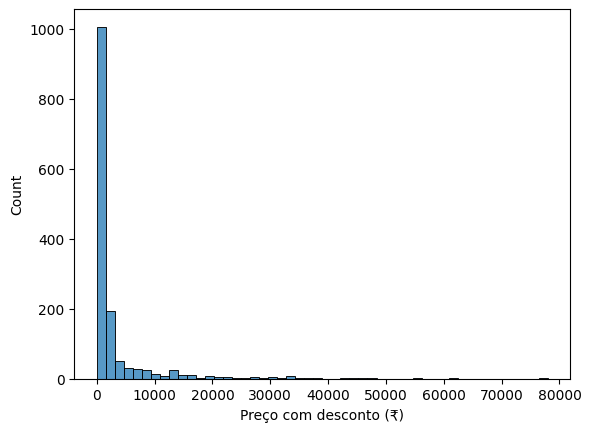

In [4]:
sns.histplot(df["discounted_price_inr"], bins=50)
plt.xlabel("Preço com desconto (₹)")
plt.show()

In [5]:
import numpy as np

# 1) Duplicados: mantém a linha com maior rating_count por product_id
df = (
    df.sort_values("rating_count", ascending=False)
      .drop_duplicates(subset="product_id", keep="first")
      .reset_index(drop=True)
)
print("Produtos únicos:", len(df))  # esperado: 1351

# 2) Categorias hierárquicas
niveis = df["category"].str.split("|")
df["cat_principal"] = niveis.str[0]
df["cat_sub"] = niveis.str[1]
df["cat_folha"] = niveis.str[-1]

# 3) Faixas (rótulos em rupias)
df["faixa_desconto"] = pd.cut(
    df["discount_pct"],
    bins=[-0.01, 0.2, 0.4, 0.6, 0.8, 1.0],
    labels=["1. 0-20%", "2. 20-40%", "3. 40-60%", "4. 60-80%", "5. 80%+"],
)

df["faixa_preco"] = pd.cut(
    df["discounted_price_inr"],
    bins=[0, 500, 1500, 5000, np.inf],
    labels=["1. Até ₹500", "2. ₹500-1.500", "3. ₹1.500-5.000", "4. Acima de ₹5.000"],
    right=False,
)

df["faixa_avaliacao"] = pd.cut(
    df["rating"],
    bins=[0, 4.0, 4.3, 5.1],
    labels=["1. Abaixo de 4,0", "2. 4,0 a 4,29", "3. 4,3 ou mais"],
    right=False,
).astype("object").fillna("Sem nota")

# 4) Quadrantes de engajamento x satisfação (cortes calculados após a deduplicação)
p75 = df["rating_count"].quantile(0.75)
p25 = df["rating_count"].quantile(0.25)
print(f"P25 = {p25:,.0f} | P75 = {p75:,.0f}")  # esperado: ~1.106 e ~16.020

def quadrante(r):
    if pd.isna(r["rating"]) or pd.isna(r["rating_count"]):
        return "Sem dados"
    alto = r["rating_count"] >= p75
    baixo = r["rating_count"] <= p25
    if alto and r["rating"] < 4:
        return "Alto engajamento, baixa nota"
    if alto and r["rating"] >= 4.3:
        return "Estrela"
    if baixo and r["rating"] >= 4.3:
        return "Joia escondida"
    return "Demais"

df["quadrante"] = df.apply(quadrante, axis=1)
print(df["quadrante"].value_counts())

Produtos únicos: 1351
P25 = 1,106 | P75 = 16,020
quadrante
Demais                          1106
Estrela                          112
Joia escondida                    81
Alto engajamento, baixa nota      49
Sem dados                          3
Name: count, dtype: int64


In [6]:
import re
from collections import Counter

# 1) Limpeza do texto: minúsculas, sem URLs e sem pontuação
def limpar(t):
    t = re.sub(r"https?://\S+", " ", str(t).lower())
    return re.sub(r"[^a-z\s]", " ", t)

df["txt"] = df["review_content"].map(limpar)

stop = set("""the and is for to a of it in i this was with on that are as but be have has not my you so very can they
its at from or one all will if by we an your me them these there also just more when than which what use used using
get got only after out up would could do does did been were his her our too much even about into other any some no
yes really still like well""".split())

# 2) Grupos de nota
df["grupo_nota"] = np.where(df["rating"] >= 4.3, "alta",
                     np.where(df["rating"] < 4.0, "baixa", "media"))
n_grupo = df["grupo_nota"].value_counts()
print(n_grupo)  # esperado: media 592, alta 419, baixa 340

# 3) Em quantos produtos de cada grupo cada palavra aparece (conta 1x por produto)
cont = {g: Counter() for g in ["alta", "baixa"]}
for g in cont:
    for t in df.loc[df["grupo_nota"] == g, "txt"]:
        cont[g].update({w for w in t.split() if len(w) > 2 and w not in stop})

linhas = []
for w in set(cont["alta"]) | set(cont["baixa"]):
    if cont["alta"][w] + cont["baixa"][w] >= 25:  # ignora palavras raras
        a = cont["alta"][w] / n_grupo["alta"]
        b = cont["baixa"][w] / n_grupo["baixa"]
        linhas.append((w, a, b, b / (a + 1e-9)))

palavras = pd.DataFrame(linhas, columns=["palavra", "%_bem_avaliados", "%_mal_avaliados", "razao_mal_vs_bem"])

print("Mais associadas a produtos MAL avaliados:")
print(palavras.sort_values("razao_mal_vs_bem", ascending=False).head(15).round(3).to_string(index=False))
print("\nMais associadas a produtos BEM avaliados:")
print(palavras.sort_values("razao_mal_vs_bem").head(15).round(3).to_string(index=False))

# 4) Temas (% de produtos do grupo que mencionam o tema)
temas = {
    "Qualidade/Durabilidade": r"quality|durab|sturdy|build|strong|last",
    "Preço/Custo-benefício": r"price|value for money|worth|cheap|budget|affordable|money",
    "Bateria/Carga": r"battery|charg|power",
    "Som/Áudio": r"sound|audio|bass|volume|speaker",
    "Defeito/Falha": r"defect|damage|stopped working|not working|broke|faulty|waste|poor|useless|issue|problem|fail",
    "Entrega/Embalagem": r"deliver|packag|packing|box|seller|received",
    "Instalação/Uso": r"install|easy to use|easy to|setup|fit",
    "Desempenho": r"fast|speed|perform|smooth|slow|noise|heat",
}
for nome, padrao in temas.items():
    df["tema_" + nome] = df["txt"].str.contains(padrao, regex=True)

tabela_temas = df.groupby("grupo_nota")[["tema_" + n for n in temas]].mean().T.round(2)
tabela_temas.index = [i.replace("tema_", "") for i in tabela_temas.index]
print(tabela_temas[["alta", "media", "baixa"]])

grupo_nota
media    592
alta     419
baixa    340
Name: count, dtype: int64
Mais associadas a produtos MAL avaliados:
palavra  %_bem_avaliados  %_mal_avaliados  razao_mal_vs_bem
    ear            0.010            0.065             6.778
   bass            0.017            0.103             6.162
  music            0.021            0.074             3.423
  noise            0.043            0.138             3.218
   cord            0.026            0.076             2.913
  waste            0.024            0.059             2.465
average            0.067            0.153             2.289
calling            0.029            0.065             2.259
    hrs            0.021            0.047             2.191
   item            0.050            0.109             2.171
 heater            0.026            0.056             2.129
    bad            0.091            0.179             1.978
    tap            0.024            0.047             1.972
    min            0.024            0.047 

In [7]:
for cat in ["Electronics", "Computers&Accessories", "Home&Kitchen"]:
    sub = df[df["cat_principal"] == cat]
    ng = sub["grupo_nota"].value_counts()
    print(f"\n=== {cat} === alta: {ng.get('alta',0)} | baixa: {ng.get('baixa',0)}")

    cont = {g: Counter() for g in ["alta", "baixa"]}
    for g in cont:
        for t in sub.loc[sub["grupo_nota"] == g, "txt"]:
            cont[g].update({w for w in t.split() if len(w) > 2 and w not in stop})

    linhas = []
    for w in set(cont["alta"]) | set(cont["baixa"]):
        if cont["alta"][w] + cont["baixa"][w] >= 15:
            a = cont["alta"][w] / max(ng.get("alta", 1), 1)
            b = cont["baixa"][w] / max(ng.get("baixa", 1), 1)
            linhas.append((w, round(a, 3), round(b, 3), round(b / (a + 1e-9), 2)))
    r = pd.DataFrame(linhas, columns=["palavra", "bem", "mal", "razao"])
    print("Mal avaliados:", r.sort_values("razao", ascending=False).head(8)["palavra"].tolist())
    print("Bem avaliados:", r.sort_values("razao").head(8)["palavra"].tolist())


=== Electronics === alta: 136 | baixa: 128
Mal avaliados: ['ears', 'cancellation', 'noise', 'wired', 'ear', 'anything', 'bass', 'chinese']
Bem avaliados: ['installed', 'write', 'installation', 'highly', 'hdmi', 'noticeable', 'storage', 'streaming']

=== Computers&Accessories === alta: 154 | baixa: 66
Mal avaliados: ['expect', 'item', 'bad', 'must', 'slow', 'useful', 'okay', 'black']
Bem avaliados: ['definitely', 'looks', 'helpful', 'make', 'right', 'never', 'lot', 'supports']

=== Home&Kitchen === alta: 106 | baixa: 144
Mal avaliados: ['poor', 'warm', 'average', 'received', 'please', 'bad', 'body', 'heating']
Bem avaliados: ['love', 'perfect', 'excellent', 'daily', 'star', 'thanks', 'happy', 'many']


In [8]:
resultados = []
for cat in ["Electronics", "Computers&Accessories", "Home&Kitchen"]:
    sub = df[df["cat_principal"] == cat]
    ng = sub["grupo_nota"].value_counts()
    cont = {g: Counter() for g in ["alta", "baixa"]}
    for g in cont:
        for t in sub.loc[sub["grupo_nota"] == g, "txt"]:
            cont[g].update({w for w in t.split() if len(w) > 2 and w not in stop})
    for w in set(cont["alta"]) | set(cont["baixa"]):
        if cont["alta"][w] + cont["baixa"][w] >= 15:
            a = cont["alta"][w] / max(ng.get("alta", 1), 1)
            b = cont["baixa"][w] / max(ng.get("baixa", 1), 1)
            resultados.append((cat, w, a, b, b / (a + 1e-9)))

palavras_cat = pd.DataFrame(resultados, columns=["categoria", "palavra", "pct_bem", "pct_mal", "razao"])
palavras_cat.to_csv("palavras_por_categoria.csv", index=False, encoding="utf-8-sig")

Para exportar e usar no Power BI:

In [9]:
cols_drop = ["user_id", "user_name", "review_id", "img_link"]
df.drop(columns=cols_drop).to_csv("amazon_tratado.csv", index=False, encoding="utf-8-sig")

In [10]:
palavras.to_csv("palavras_grupos.csv", index=False, encoding="utf-8-sig")
tabela_temas.reset_index(names="tema").to_csv("temas_grupos.csv", index=False, encoding="utf-8-sig")

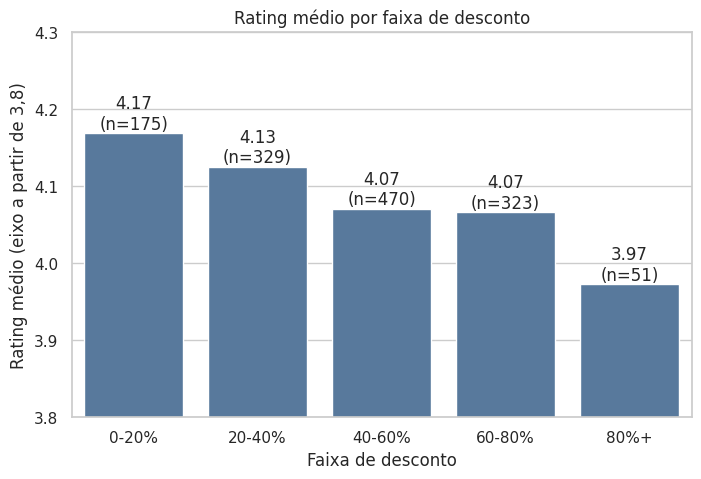

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Salvo: graficos_png/g1_rating_por_faixa_desconto.png


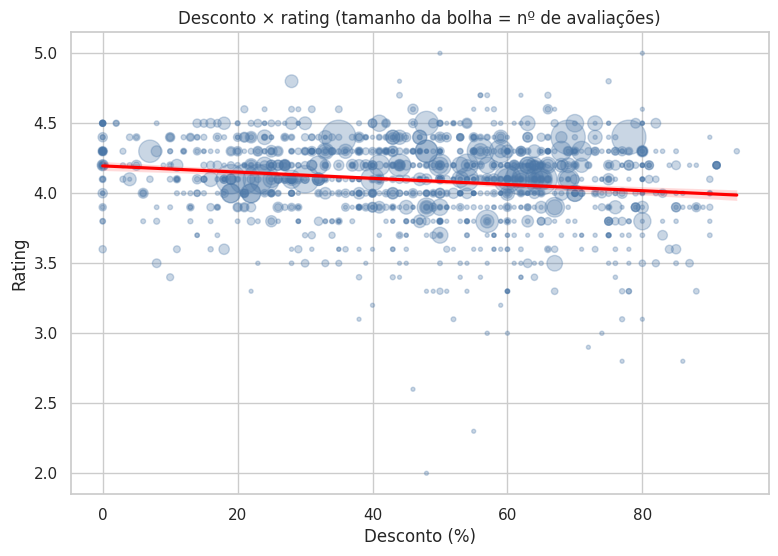

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Salvo: graficos_png/g2_dispersao_desconto_rating.png


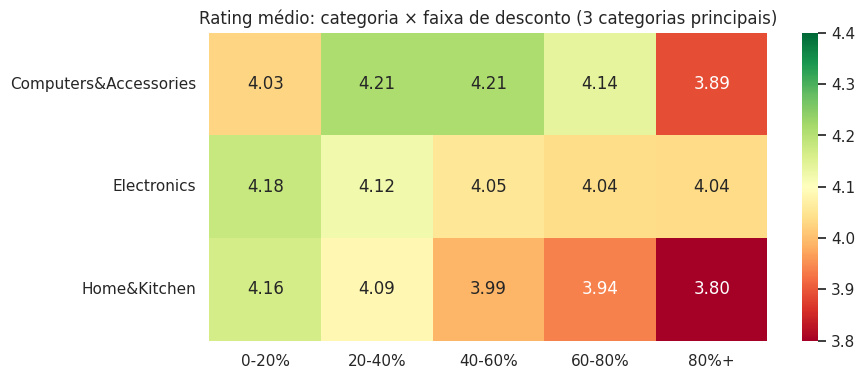

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Salvo: graficos_png/g3_heatmap_categoria_desconto.png


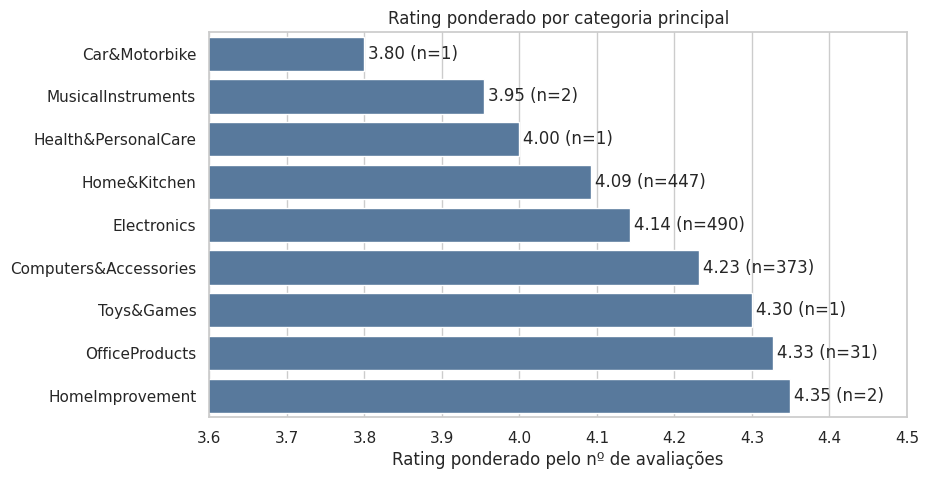

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Salvo: graficos_png/g4_rating_por_categoria.png


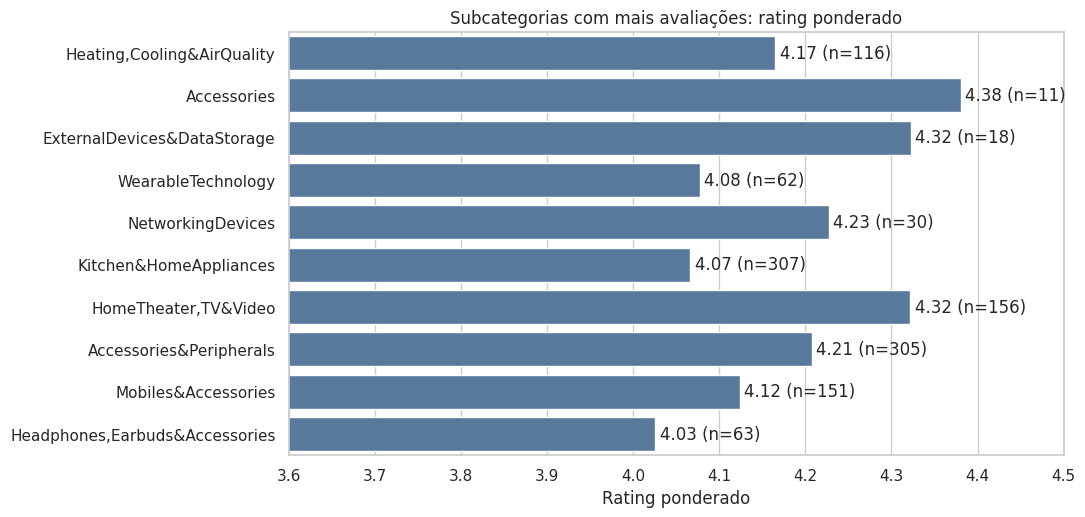

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Salvo: graficos_png/g5_subcategorias.png


In [11]:
import pandas as pd, numpy as np, os
import matplotlib.pyplot as plt
import seaborn as sns

try:
    from google.colab import files
    NO_COLAB = True
except ImportError:
    NO_COLAB = False

sns.set_theme(style="whitegrid")
PASTA = "graficos_png"
os.makedirs(PASTA, exist_ok=True)

def salvar(fig, nome):
    """Salva o gráfico em PNG (200 dpi), mostra na tela e baixa o arquivo direto."""
    caminho = f"{PASTA}/{nome}.png"
    fig.savefig(caminho, dpi=200, bbox_inches="tight", facecolor="white")
    plt.show()
    if NO_COLAB:
        files.download(caminho)
    print("Salvo:", caminho)

# ---------- 1) Tratamento ----------
df = pd.read_csv("amazon.csv")
for col in ["discounted_price", "actual_price"]:
    df[col + "_inr"] = pd.to_numeric(
        df[col].str.replace("₹", "", regex=False).str.replace(",", "", regex=False), errors="coerce")
df["discount_pct"] = pd.to_numeric(df["discount_percentage"].str.replace("%", "", regex=False), errors="coerce") / 100
df["rating"] = pd.to_numeric(df["rating"], errors="coerce")
df["rating_count"] = pd.to_numeric(df["rating_count"].str.replace(",", "", regex=False), errors="coerce")

# Duplicados: mantém a linha com mais avaliações; empate -> maior preço com desconto
df = (df.sort_values(["rating_count", "discounted_price_inr"], ascending=False)
        .drop_duplicates("product_id").reset_index(drop=True))

niv = df["category"].str.split("|")
df["cat_principal"], df["cat_sub"] = niv.str[0], niv.str[1]
df["faixa_desconto"] = pd.cut(df["discount_pct"], [-0.01, .2, .4, .6, .8, 1.0],
                              labels=["0-20%", "20-40%", "40-60%", "60-80%", "80%+"])

base = df.dropna(subset=["rating", "rating_count"]).copy()
base["r_x_c"] = base["rating"] * base["rating_count"]
principais = ["Electronics", "Computers&Accessories", "Home&Kitchen"]

def resumo(chave):
    t = base.groupby(chave, observed=True).agg(
        n=("rating", "size"), rating_medio=("rating", "mean"),
        aval_total=("rating_count", "sum"), soma_rc=("r_x_c", "sum"))
    t["rating_pond"] = t["soma_rc"] / t["aval_total"]
    return t.drop(columns="soma_rc")

faixa = resumo("faixa_desconto")
cat = resumo("cat_principal").sort_values("aval_total", ascending=False)
sub = resumo("cat_sub")
sub = sub[sub["n"] >= 10].sort_values("aval_total", ascending=False).head(10)
heat = (base[base["cat_principal"].isin(principais)]
        .pivot_table(index="cat_principal", columns="faixa_desconto",
                     values="rating", aggfunc="mean", observed=True))

# ---------- 2) Gráficos (cada um é salvo e baixado em PNG) ----------
# G1: rating médio por faixa de desconto
fig, ax = plt.subplots(figsize=(8, 5))
sns.barplot(x=faixa.index.astype(str), y=faixa["rating_medio"], ax=ax, color="#4C78A8")
ax.set_ylim(3.8, 4.3)
for i, (r, n) in enumerate(zip(faixa["rating_medio"], faixa["n"])):
    ax.text(i, r + 0.005, f"{r:.2f}\n(n={int(n)})", ha="center")
ax.set_title("Rating médio por faixa de desconto")
ax.set_xlabel("Faixa de desconto"); ax.set_ylabel("Rating médio (eixo a partir de 3,8)")
salvar(fig, "g1_rating_por_faixa_desconto")

# G2: dispersão desconto x rating
fig, ax = plt.subplots(figsize=(9, 6))
ax.scatter(base["discount_pct"] * 100, base["rating"],
           s=base["rating_count"] / base["rating_count"].max() * 600 + 8, alpha=.3, color="#4C78A8")
sns.regplot(x=base["discount_pct"] * 100, y=base["rating"], scatter=False, color="red", ax=ax)
ax.set_title("Desconto × rating (tamanho da bolha = nº de avaliações)")
ax.set_xlabel("Desconto (%)"); ax.set_ylabel("Rating")
salvar(fig, "g2_dispersao_desconto_rating")

# G3: heatmap categoria x faixa de desconto
fig, ax = plt.subplots(figsize=(9, 4))
sns.heatmap(heat, annot=True, fmt=".2f", cmap="RdYlGn", vmin=3.8, vmax=4.4, ax=ax)
ax.set_title("Rating médio: categoria × faixa de desconto (3 categorias principais)")
ax.set_xlabel(""); ax.set_ylabel("")
salvar(fig, "g3_heatmap_categoria_desconto")

# G4: rating ponderado por categoria principal
fig, ax = plt.subplots(figsize=(9, 5))
cc = cat.sort_values("rating_pond")
sns.barplot(y=cc.index, x=cc["rating_pond"], ax=ax, color="#4C78A8")
ax.set_xlim(3.6, 4.5)
for i, (r, n) in enumerate(zip(cc["rating_pond"], cc["n"])):
    ax.text(r + 0.005, i, f"{r:.2f} (n={int(n)})", va="center")
ax.set_title("Rating ponderado por categoria principal")
ax.set_xlabel("Rating ponderado pelo nº de avaliações"); ax.set_ylabel("")
salvar(fig, "g4_rating_por_categoria")

# G5: subcategorias com mais avaliações
fig, ax = plt.subplots(figsize=(10, 5.5))
ss = sub.sort_values("aval_total")
sns.barplot(y=ss.index, x=ss["rating_pond"], ax=ax, color="#4C78A8")
ax.set_xlim(3.6, 4.5)
for i, (r, n) in enumerate(zip(ss["rating_pond"], ss["n"])):
    ax.text(r + 0.005, i, f"{r:.2f} (n={int(n)})", va="center")
ax.set_title("Subcategorias com mais avaliações: rating ponderado")
ax.set_xlabel("Rating ponderado"); ax.set_ylabel("")
salvar(fig, "g5_subcategorias")